# Walk-through: one gene, start to finish

This notebook follows a single RNAi condition through the whole downstream pipeline of Green et al. 2024
(*Cell*), using the ported code in `src/embd/` and the published data in `data/`. Every number below is
computed live by the same functions the pipeline uses, and checked against the frozen outputs of the
**original** Python 2.7 code (`tests/golden/`).

**Our gene: EMBD0087, *apr-1*** (the *C. elegans* APC homologue, a Wnt-pathway component). In the screen its
embryos show a strong **rupture** phenotype. It is not one of the hand-picked "manual group" genes, so the
description the pipeline gives it is genuinely inferred.

**The pipeline in one picture**

```
 spreadsheet (one row per gene: ~138 measurements x 2 reporter strains)
   │  1. pick a parameter set, normalise each gene against wild-type control  ->  a vector per gene
   │  2. distance between two genes' vectors (over the measurements both have)
   │  3. PAD (phenotypic angle of deviation) = how similar two genes are, relative to how far each is from wild type (0 = unrelated, 1 = identical)
   ▼
 phenoDist CSV: dist / PAD / CSI for all 503 x 503 pairs              (phenoDistCalc)
   ├─► best matches per gene, PAD_RANK table (top 50)                 (PADassist)
   ├─► top hits, reciprocal matches, WT-like / phenotype              (db_utils_genes)
   ├─► auto-description: closest of 17 hand-curated phenotype groups  (groupAssesment)
   └─► PAD matrix  ─►  UMAP map of all genes                          (groupAssesment, makeUMAPs_V2)
```

Everything runs in a scratch folder (`build/walkthrough/`), takes about a minute in total and well under 1 GB of
memory. Run the cells in order (*Run All* works).

## 0. Setup

The original code read its inputs from a lab file server (`Z:/`) and a MySQL database. The port replaces those
with a folder (`EMBD_OUT_DIR`) and a small SQLite file built from the published spreadsheet (`EMBD_SQLITE`).
`EMBD_PARAMSET=opt` selects the *optimal* parameter set used for the paper's main results. These must be set
**before** importing `embd`, because the original modules read them once, at import time.

In [1]:
import os, sys, pathlib, contextlib, io, warnings
warnings.filterwarnings('ignore')   # library chatter (tqdm, umap); none of it affects results
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
WORK = ROOT / 'build' / 'walkthrough'
WORK.mkdir(parents=True, exist_ok=True)
os.environ.update(EMBD_OUT_DIR=str(WORK) + '/', EMBD_SQLITE=str(WORK / 'embd.sqlite'), EMBD_PARAMSET='opt')
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.width', 140)

GENE = 87          # EMBD0087, apr-1
quiet = lambda: contextlib.redirect_stdout(io.StringIO())   # the original code prints a lot; hide it

In [2]:
# Spreadsheet -> canonical CSV -> SQLite "MySQL" database (exactly what `pipeline reproduce` does first)
from embd_data import sheet
from embd import pipeline

canon = WORK / 'canonical'
canon.mkdir(exist_ok=True)
sheet.convert_genes_table(str(ROOT / 'data/All_genes_mySQL_table.xlsx'), str(canon / 'genes_table.csv'))
sheet.write_gene_key(str(ROOT / 'data/Index_EMBD_ID_Gene_names.xlsx'), str(canon / 'gene_key.csv'))
if os.path.exists(os.environ['EMBD_SQLITE']):
    os.remove(os.environ['EMBD_SQLITE'])
pipeline.init_db(str(canon / 'genes_table.csv'), str(canon / 'gene_key.csv'))

from embd.embdFunc import getGeneCommonName
print('EMBD%04d is %s' % (GENE, getGeneCommonName(GENE)))

EMBD0087 is apr-1


## 1. The input: one row of measurements per gene

Each RNAi condition was filmed in two reporter strains:

* **GLS**, the *germ-layer* strain: three fluorescent channels marking the three germ layers (counts of nuclei over time);
* **MS**, the *morphogenesis* strain: markers whose intensity and shape follow how the embryo elongates.

Image analysis (not part of this port) fitted curves to every embryo's movie and stored, per gene, the median of
each fitted parameter: `aG` = plateau of the green curve, `mG` = its midpoint in time, `sG` = its width, and so
on (see `docs/PARAMETER_TABLE.md`). Empty cells mean the parameter could not be measured reliably for that gene.

In [3]:
table = pd.read_csv(canon / 'genes_table.csv', low_memory=False)
row = table[table.embd_id == GENE].iloc[0]
print('columns in the table:', table.shape[1], '| genes (rows):', table.shape[0])
row[['embd_id', 'gene_name', 'movement_GLS', 'movement_MS', 'aG_GLS', 'mG_GLS', 'sG_GLS', 'aR_MS', 'maxHead_MS']]

columns in the table: 235 | genes (rows): 514


embd_id                          87
gene_name       2022-04-01 00:00:00
movement_GLS                    0.0
movement_MS                     0.0
aG_GLS                      93.7245
mG_GLS                      1.16855
sG_GLS                     0.942444
aR_MS                   475466000.0
maxHead_MS                   2.8095
Name: 87, dtype: object

`movement_GLS` / `movement_MS` record whether embryos started moving inside the eggshell (1) or not (0). For
*apr-1* they are 0, so the embryos arrest before moving: a **phenotype**.

*Aside:* `gene_name` shows `2022-04-01`. That is Excel turning "APR-1" into April 1st, a classic
problem with gene names in spreadsheets (DECISIONS A16). The pipeline takes names from the gene index instead,
where the port converts the date back to `apr-1`.

## 2. Which measurements count: the parameter set

Not every measurement is informative. The authors chose an **optimal set** of 17 GLS and 24 MS parameters (in
`params_use_assign._group_rank_opt`) that best separated their hand-curated phenotype groups. The pipeline also
runs three alternative sets (GLS-only, MS-only, all parameters); we stick to the optimal one.

In [4]:
with quiet():                 # importing the original modules prints the parameter lists
    from embd.RNAiClass import RNAiClass, PARAM_NAMES_USE_GLS, PARAM_NAMES_USE_MS
print(len(PARAM_NAMES_USE_GLS), 'GLS parameters:', ', '.join(PARAM_NAMES_USE_GLS))
print(len(PARAM_NAMES_USE_MS), 'MS parameters: ', ', '.join(PARAM_NAMES_USE_MS))

17 GLS parameters: maxG, aG, sY, fracR, fracG, CoM0Rtd_GLS, CoM1Rscale_GLS, MoI0GavgRes_GLS, MoI1Gscale_GLS, MoI1GstdTail_GLS, MoI0Rtd_GLS, MoI0RavgRes_GLS, MoI1Rtd_GLS, MoI0Ytd_GLS, MoI0YavgRes_GLS, MoI1Yscale_GLS, MoI1YavgRes_GLS
24 MS parameters:  sG, maxR, aR, sR, maxHead, tailHead, devHead, devLength, tailLength, CoM0Gtd_MS, CoM0Gscale_MS, CoM1Gscale_MS, CoM1GavgRes_MS, CoM0Rscale_MS, CoM0RavgRes_MS, CoM1Rtd_MS, CoM1RavgRes_MS, CoM1RstdTail_MS, MoI0Gscale_MS, MoI1Gscale_MS, MoI1GstdTail_MS, MoI1Rscale_MS, MoI1RavgRes_MS, MoI1RstdTail_MS


## 3. Turning a gene into a vector: normalising against wild type

`RNAiClass(87)` loads the gene's row; `setNDPosition()` turns it into a position in "phenotype space". For each
parameter in the set:

$$\text{position} = \frac{\text{gene's value} - \text{wild-type control mean}}{\text{spread of that parameter across all RNAi conditions}}$$

So 0 means "exactly like wild type", and +2 means "two typical spreads above wild type". The control means and
spreads are fixed numbers copied from the original code (`_rnai_constants.py`). Unmeasured parameters stay `NaN`
and are simply left out later. Below we recompute a few by hand and compare.

In [5]:
with quiet():
    r = RNAiClass(GENE, verb=False)
    r.setNDPosition()

rows = []
for p in PARAM_NAMES_USE_GLS[:6]:
    k = p + '_GLS'
    by_hand = (r.paramsGLS[p] - r.origin[k]) / r.paramNorms[k]
    rows.append({'parameter': k, 'apr-1 value': r.paramsGLS[p], 'control mean': r.origin[k],
                 'spread (all RNAi)': r.paramNorms[k], 'by hand': by_hand})
df = pd.DataFrame(rows)
from embd.varLookup import PARAM_NAMES
df['RNAiClass.posND'] = [r.posND[PARAM_NAMES.index(p)] for p in PARAM_NAMES_USE_GLS[:6]]
df

,parameter,apr-1 value,control mean,spread (all RNAi),by hand,RNAiClass.posND
0,maxG_GLS,1.341370e+09,1.349350e+09,2.547180e+08,-0.031328,-0.031328
1,aG_GLS,9.372450e+01,8.934486e+01,1.748630e+01,0.250462,0.250462
2,sY_GLS,1.388190e+00,1.366897e+00,5.018504e-01,0.042429,0.042429
3,fracR_GLS,3.973540e-01,3.893110e-01,7.225929e-02,0.111307,0.111307
4,fracG_GLS,3.275150e-01,3.197629e-01,5.326791e-02,0.145531,0.145531
5,CoM0Rtd_GLS_GLS,1.700000e+01,1.613603e+01,3.800228e+00,0.227347,0.227347


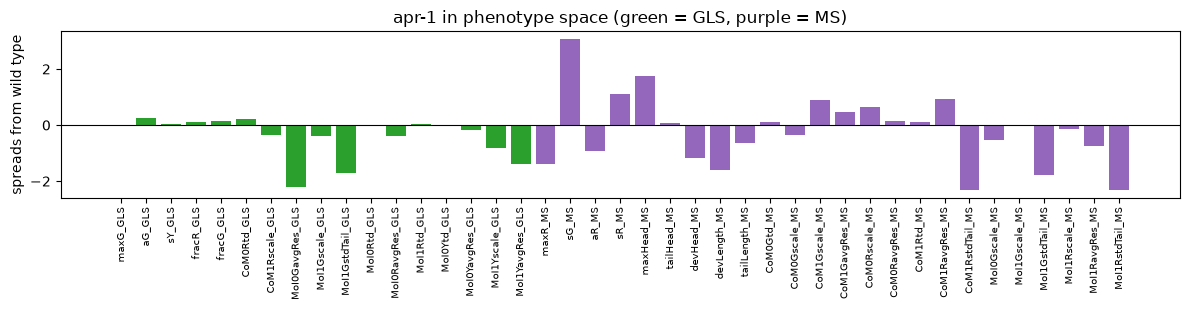

measured parameters in the set: 41 of 41


In [6]:
v = r.posND                               # 276 slots: 138 GLS then 138 MS; only the 41 in the set are filled
used = ~np.isnan(v)
names = [PARAM_NAMES[i % 138] + ('_GLS' if i < 138 else '_MS') for i in np.where(used)[0]]
names = [n.replace('_GLS_GLS', '_GLS').replace('_MS_MS', '_MS') for n in names]
plt.figure(figsize=(12, 3.2))
plt.bar(range(used.sum()), v[used], color=['tab:green' if n.endswith('_GLS') else 'tab:purple' for n in names])
plt.xticks(range(used.sum()), names, rotation=90, fontsize=7); plt.axhline(0, color='k', lw=0.8)
plt.ylabel('spreads from wild type'); plt.title('apr-1 in phenotype space (green = GLS, purple = MS)')
plt.tight_layout(); plt.show()
print('measured parameters in the set:', used.sum(), 'of', len(PARAM_NAMES_USE_GLS) + len(PARAM_NAMES_USE_MS))

## 4. How far from wild type?

The **distance to wild type** is the ordinary (Euclidean) length of that vector: the square root of the sum of
squares. If a gene is missing some parameters, the distance is scaled up by $\sqrt{N / n_\text{measured}}$ so
genes with gaps are not made to look artificially close to normal (`embdFunc.getNDDistance`).

In [7]:
N = len(PARAM_NAMES_USE_GLS) + len(PARAM_NAMES_USE_MS)
by_hand = np.sqrt(N / used.sum()) * np.sqrt(np.sum(v[used] ** 2))
print('distance to wild type, by hand :', by_hand)
print('RNAiClass.getDist2Zero()       :', r.getDist2Zero())

distance to wild type, by hand : 7.008489991073618
RNAiClass.getDist2Zero()       : 7.008489991073618


## 5. Comparing two genes: distance and PAD

The distance between two genes uses only the parameters **both** have, with the same kind of penalty for the
ones only one of them has:

$$d(A,B) = \sqrt{\frac{N}{N - i_A - i_B}}\;\lVert A - B \rVert_\text{shared}$$

where $i_A$ / $i_B$ count parameters only A / only B has. On its own, a distance is hard to interpret: two
severe phenotypes can be far apart in absolute terms yet clearly related. **PAD**, the *phenotypic angle of deviation*
(Green et al. 2024), rescales it by how far each gene is from wild type:

$$\text{PAD}(A,B) = 1 - \frac{d(A,B)}{d(A,\text{WT}) + d(B,\text{WT})}, \quad\text{clipped at 0}$$

By the triangle inequality the ratio is between 0 and 1, so PAD = 1 means identical positions and PAD near 0
means unrelated (or one of them is wild type). The paper describes the ratio itself (lower = more similar); the code
stores 1 minus the ratio, so in every output below **higher PAD = more similar**. Like an angle, PAD ignores how
severe two phenotypes are and asks whether they deviate from wild type in the same direction. Let's compare *apr-1* with *let-502* (EMBD0007), which step 7 finds as its best match.

In [8]:
with quiet():
    b = RNAiClass(7, verb=False)          # EMBD0007
    b.setNDPosition()
print('partner: EMBD%04d %s' % (b.RNAi, getGeneCommonName(b.RNAi)))

A, B = r.posND, b.posND
shared = ~np.isnan(A) & ~np.isnan(B)
iA = np.sum(~np.isnan(A)) - shared.sum(); iB = np.sum(~np.isnan(B)) - shared.sum()
d = np.sqrt(N / (N - iA - iB)) * np.sqrt(np.sum((A - B)[shared] ** 2))
pad = 1 - d / (r.getDist2Zero() + b.getDist2Zero())
print('shared parameters: %d, only apr-1: %d, only partner: %d' % (shared.sum(), iA, iB))
print('distance  by hand %.12f   getDistance %.12f' % (d, r.getDistance(b)))
print('PAD       by hand %.12f   getPAD      %.12f' % (pad, r.getPAD(b)))

partner: EMBD0007 let-502
shared parameters: 41, only apr-1: 0, only partner: 0
distance  by hand 4.495016586312   getDistance 4.495016586312
PAD       by hand 0.646656001699   getPAD      0.646656001699


## 6. All pairs at once: the phenoDist file

`phenoDistCalc` does step 5 for **every** pair of the 503 conditions (253,009 pairs) and writes one CSV row per
pair: distance, distance to wild type, number of shared parameters (`dims`), CSI and PAD. CSI is an older
neighbourhood-based score that the code still computes; none of the published outputs below uses it.

In the original this took ~45 minutes per parameter set; the port's vectorised version takes a few seconds and
writes a byte-identical file.

In [9]:
import time
t0 = time.time()
with quiet():
    pipeline.phenodist('opt')
print('phenoDist for all pairs: %.1f s' % (time.time() - t0))
pd_file = WORK / pipeline.PHENODIST['opt']
print(open(pd_file).read().splitlines()[2])
pairs = pd.read_csv(pd_file, skiprows=2)
pairs[pairs.RNA1 == 'EMBD%04d' % GENE].sort_values('PAD', ascending=False).head(6)

phenoDist for all pairs: 5.1 s
RNA1,RNA2,dist,dist2WT,dims,CSI,PAD


,RNA1,RNA2,dist,dist2WT,dims,CSI,PAD
43760,EMBD0087,EMBD0087,0.000000,7.00849,41,0.998012,1.000000
43759,EMBD0087,EMBD0007,4.495017,7.00849,41,0.974155,0.646656
43758,EMBD0087,EMBD0057,4.933145,7.00849,41,0.956262,0.637427
43757,EMBD0087,EMBD0010,5.104612,7.00849,41,0.962227,0.630949
43752,EMBD0087,EMBD0441,5.314720,7.00849,41,0.964215,0.621799
43755,EMBD0087,EMBD0369,5.211853,7.00849,41,0.974155,0.617407


The first row is *apr-1* against itself (PAD = 1); the pipeline always skips it. The PAD scores of *apr-1* to
all other genes look like this: most genes are only loosely related (PAD 0.2-0.4), and a tail is clearly
similar (for *apr-1*, 47 genes above 0.5 and 22 above 0.55). The summaries below only ever look at the top 10.

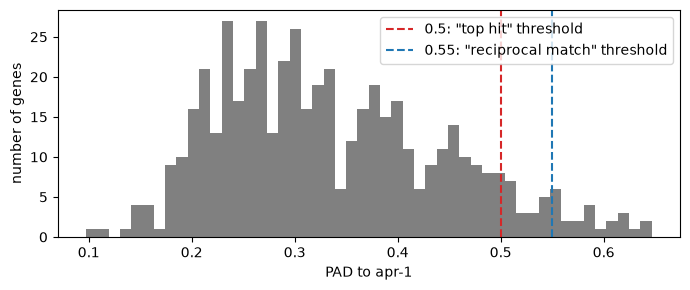

In [10]:
mine = pairs[(pairs.RNA1 == 'EMBD%04d' % GENE) & (pairs.RNA2 != 'EMBD%04d' % GENE)]
plt.figure(figsize=(7, 3)); plt.hist(mine.PAD, bins=50, color='grey')
plt.axvline(0.5, color='tab:red', ls='--', label='0.5: "top hit" threshold')
plt.axvline(0.55, color='tab:blue', ls='--', label='0.55: "reciprocal match" threshold')
plt.xlabel('PAD to apr-1'); plt.ylabel('number of genes'); plt.legend(); plt.tight_layout(); plt.show()

## 7. Best matches and PAD_RANK

`PADassist.PADFilter` sorts a gene's rows by PAD and returns the top *n* (skipping itself). The pipeline uses it
for the best-match spreadsheets (top 10, for each of the four parameter sets) and for the **PAD_RANK** table
(top 50 per gene; the code asks for 51 but the table only has 50 rank columns), which the next steps
read from.

In [11]:
from embd import PADassist
data = PADassist.get_data()                   # the phenoDist rows, as the original reads them
top10 = PADassist.PADFilter(GENE, data, 10)
pd.DataFrame([(i + 1, h, getGeneCommonName(int(h[4:])), p, int(dims)) for i, (h, p, dims) in enumerate(top10)],
             columns=['rank', 'hit', 'gene', 'PAD', 'shared params'])

,rank,hit,gene,PAD,shared params
0,1,EMBD0007,let-502,0.646656,41
1,2,EMBD0057,hmr-1,0.637427,41
2,3,EMBD0010,unc-52,0.630949,41
3,4,EMBD0441,nbet-1,0.621799,41
4,5,EMBD0369,F56F11.4,0.617407,41
5,6,EMBD0045,mlc-5,0.616637,41
6,7,EMBD0052,lin-26,0.610845,41
7,8,EMBD0054,let-413,0.606790,41
8,9,EMBD0005,gex-2,0.594839,41
9,10,EMBD0336,msp-152,0.590147,41


In [12]:
with quiet():
    pipeline.padrank()                        # writes PAD_RANK for all 503 genes into the SQLite db

import csv
mine = next(row for row in csv.DictReader(open(WORK / 'pad_rank_port.csv')) if row['rnai'] == str(GENE))
gold = next(row for row in csv.DictReader(open(ROOT / 'tests/golden/pad_rank.csv')) if row['rnai'] == str(GENE))
same_ranks = all(mine['rank%d' % k] == gold['rank%d' % k] for k in range(1, 51))
print('top-50 ranking identical to the original Python 2.7 output:', same_ranks)
print('first five:', [getGeneCommonName(int(mine['rank%d' % k])) for k in range(1, 6)])

top-50 ranking identical to the original Python 2.7 output: True
first five: ['let-502', 'hmr-1', 'unc-52', 'nbet-1', 'F56F11.4']


## 8. Top hits and reciprocal matches

Two summary columns for the database / website:

* **top hits**: the gene's top 10, keeping only those with PAD > 0.5;
* **reciprocal matches**: of the top 10 with PAD > 0.55, those that *also* have our gene in **their** top 10.
  "We look like each other from both sides" is stronger evidence than a one-way match.

In [13]:
from embd.db_utils_embryos import initialize_db
from embd import db_utils_genes
conn, curs = initialize_db()

def top10_of(g):
    curs.execute('SELECT %s FROM PAD_RANK WHERE rnai=%d' % (','.join('rank%d' % k for k in range(1, 11)), g))
    return list(curs.fetchone())

top_hits = [int(h[4:]) for h, p, _ in top10 if p > 0.5]
by_hand = [int(h[4:]) for h, p, _ in top10 if p > 0.55 and GENE in top10_of(int(h[4:]))]
with quiet():
    by_code = db_utils_genes.get_reciprocal_matches(GENE, 10, curs, thr=0.55)
print('top hits           :', ', '.join(getGeneCommonName(g) for g in top_hits))
print('reciprocal, by hand:', ', '.join(getGeneCommonName(g) for g in by_hand))
print('reciprocal, code   :', ', '.join(getGeneCommonName(int(g)) for g in by_code))

top hits           : let-502, hmr-1, unc-52, nbet-1, F56F11.4, mlc-5, lin-26, let-413, gex-2, msp-152
reciprocal, by hand: let-502, F56F11.4, gex-2, msp-152
reciprocal, code   : let-502, F56F11.4, gex-2, msp-152


## 9. An automatic description: the closest curated group

The authors hand-sorted 91 genes into **17 phenotype groups** ("early arrest with excess ectoderm", "rupture",
"late elongation arrest", ...). `groupAssesment` averages each group's vectors into a centre, computes the PAD
from our gene to every centre, and turns the best one into a sentence:

* best group PAD < 0.5 → "does not closely match any group" (0.35 is enough for the broad *wild-type* and
  *developmental delay* groups);
* groups within 5% of the best are all reported (e.g. a gene between two groups), unless the best is below 0.55.

In [14]:
with quiet():
    from embd import groupAssesment
    from embd.embdFunc import getNDDistance
    from embd.params_use_assign import get_params_use
    names, centres = groupAssesment.calculate_avg_vectors_man_groups()
    PU = get_params_use()                          # prints the parameter lists on every call
rows = []
for name, c in zip(names, centres):
    dist = getNDDistance(r.posND, c, PU)
    if np.isinf(dist):
        dist = 0.                                  # original quirk (no shared parameters -> PAD 1); Q9 in the docs
    p = 1 - dist / (r.getDist2Zero() + getNDDistance(c, 'control', PU))
    rows.append({'rna': GENE, 'group': name, 'PAD': p if p > 0 else np.nan, 'Dist': dist})
groups = pd.DataFrame(rows)
display(groups.sort_values('PAD', ascending=False).head(5))
group, description = groupAssesment.get_closest_group_description(groups)
print(group, '->', description)

,rna,group,PAD,Dist
8,87,rupture,0.635333,4.661256
7,87,dorsBend,0.592617,5.471994
11,87,2xCrunch,0.575636,5.093899
5,87,hiNeur,0.561297,6.058112
15,87,CFS_lGlY,0.482435,6.977452


['rupture'] -> Embryos exhibit strong rupture phenotype in both reporter strains.


## 10. WT-like or phenotype?

The simplest call: if embryos in either strain failed to move, it is a **Phenotype**; if both moved, it is
**WT-like**, or **Dev. Delay** when the description says the embryos develop slowly. The real pipeline runs all of
these steps for all genes (`pipeline derived`); here we compare the result for our gene with the original output.

In [15]:
with quiet():
    pipeline.derived()
port = pd.read_csv(WORK / 'genes_derived_port.csv').set_index('embd_id').loc[GENE]
gold = pd.read_csv(ROOT / 'tests/golden/genes_derived.csv').set_index('embd_id').loc[GENE]
pd.DataFrame({'port (Python 3)': port, 'original (Python 2.7)': gold, 'same': port.astype(str) == gold.astype(str)})

,port (Python 3),original (Python 2.7),same
movement_GLS,0.0,0.0,True
movement_MS,0.0,0.0,True
auto_description,Embryos exhibit strong rupture phenotype in bo...,Embryos exhibit strong rupture phenotype in bo...,True
WT_like_or_phenotype,Phenotype,Phenotype,True
top_hits_PAD,"let-502, hmr-1, unc-52, nbet-1, F56F11.4, mlc-...","let-502, hmr-1, unc-52, nbet-1, F56F11.4, mlc-...",True
reciprocal_matches,"let-502, F56F11.4, gex-2, msp-152","let-502, F56F11.4, gex-2, msp-152",True


## 11. The map: UMAP of all 503 genes

Finally, the PAD scores of every gene to every other gene (a 503 x 503 matrix) are squeezed into two dimensions
with UMAP, so genes with similar phenotypes land near each other. The layout is seeded (`random_state=71076`), so
it is the same every run on the same machine. Small differences between machines are expected and harmless
(docs/NUMERICAL_DIFFERENCES.md, N3). Below, *apr-1*, its top hits and its reciprocal matches are highlighted.

In [16]:
with quiet():
    pipeline.matrices('opt')                       # PAD and distance matrices (503 x 503)
    from embd import makeUMAPs_V2
    M = np.load(WORK / 'PAD_Matrix_opt.npy')
    pts = makeUMAPs_V2.run(M, query=GENE, common_name=getGeneCommonName(GENE))   # same call as `pipeline umap`
print('UMAP coordinates:', pts.shape)

UMAP coordinates: (503, 2)


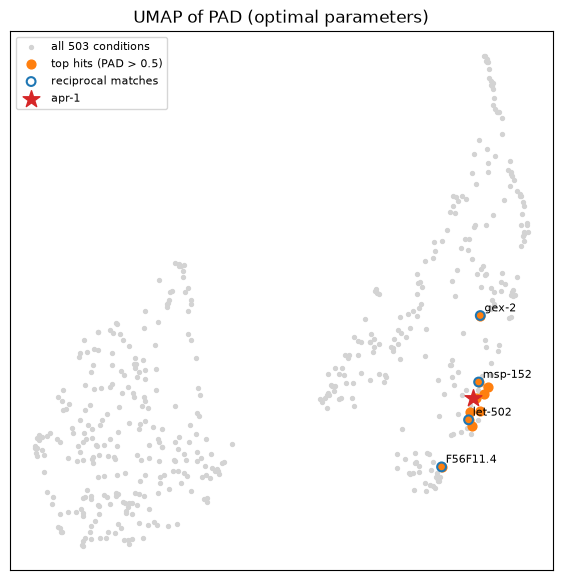

In [17]:
# makeUMAPs_V2 switches matplotlib to a file-only backend and a poster style (as the original); undo that here
plt.rcdefaults()
%matplotlib inline
idx = lambda gs: [g - 1 for g in gs]               # EMBD n is row n-1
plt.figure(figsize=(7, 7))
plt.scatter(pts[:, 0], pts[:, 1], s=8, color='lightgrey', label='all 503 conditions')
plt.scatter(*pts[idx(top_hits)].T, s=40, color='tab:orange', label='top hits (PAD > 0.5)')
plt.scatter(*pts[idx(by_code)].T, s=40, facecolor='none', edgecolor='tab:blue', lw=1.5, label='reciprocal matches')
plt.scatter(*pts[GENE - 1], s=160, marker='*', color='tab:red', label='apr-1')
for g in by_code:
    plt.annotate(getGeneCommonName(g), pts[g - 1], fontsize=8, xytext=(3, 3), textcoords='offset points')
plt.legend(loc='best', fontsize=8); plt.title('UMAP of PAD (optimal parameters)'); plt.xticks([]); plt.yticks([])
plt.show()

## Where to look in the code

| Step | Function(s) | File |
|---|---|---|
| spreadsheet → database | `convert_genes_table`, `init_db` | `src/embd_data/sheet.py`, `mysql_emulation.py` |
| parameter sets | `get_params_use`, `_group_rank_opt` | `src/embd/params_use_assign.py` |
| vector per gene | `RNAiClass.setNDPosition`, `setOrigin` | `src/embd/RNAiClass.py` |
| distance, PAD | `getNDDistance`, `RNAiClass.getDistance`, `getDist2Zero`, `getPAD` | `src/embd/embdFunc.py`, `RNAiClass.py` |
| all pairs (fast) | `run_phenodistcalc_populate`, `getPADS_all`, `getCSI_vectorized` | `src/embd/phenoDistCalc.py`, `_fast.py` |
| best matches, PAD_RANK | `PADFilter`, `output_all_best_matches_*`, `update_pad_rank` | `src/embd/PADassist.py` |
| top hits, reciprocal, WT-like | `update_top_hits_PAD`, `get_reciprocal_matches`, `update_WT_like_or_phenotype` | `src/embd/db_utils_genes.py` |
| auto-description | `calculate_avg_vectors_man_groups`, `find_closest_groups`, `get_closest_group_description` | `src/embd/groupAssesment.py` |
| matrices, UMAP | `make_UMAP_content_files`, `makeUMAPs_V2.run` | `src/embd/groupAssesment.py`, `makeUMAPs_V2.py` |
| the whole thing, in order | `reproduce`, `main('all')` | `src/embd/pipeline.py` |

**Things to try:** change `GENE` in the setup cell (e.g. 18 = *ceh-43*, late elongation arrest; 426 = early
arrest before markers; 260 = a wild-type-like gene) and *Run All*; or set `EMBD_PARAMSET='gls'` (germ-layer
parameters only) and see which matches survive.